# Maaş Tahmini — Geliştirilmiş Model

Bu notebook, `class.ipynb` içindeki **Linear Regression** modelinin skorunu geçmek için hazırlandı.

| | Orijinal model | Bu notebook |
|---|---|---|
| Model | LinearRegression | RandomForest + GradientBoosting (Voting) |
| Test R² | **0.6656** | aşağıda hesaplanıyor |

Karşılaştırmanın adil olması için **aynı veri, aynı `train_test_split(test_size=0.2, random_state=42)`** kullanılıyor.

## 1. Veriyi yükle

In [1]:
import pandas as pd, numpy as np, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

raw = pd.read_csv("Salary_Data.csv").dropna()
print(raw.shape)
raw.head()

(6698, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


## 2. Orijinal modeli birebir yeniden üret (baseline)
`class.ipynb` ile aynı adımlar: LabelEncoder → IQR → `Age` sil → split → StandardScaler → LinearRegression.

In [2]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

b = raw.copy()
le = LabelEncoder()
for c in ["Gender", "Education Level", "Job Title"]:
    b[c] = le.fit_transform(b[c])
q1, q3 = b["Salary"].quantile([.25, .75]); iqr = q3 - q1
n_before = len(b)
b = b[(b["Salary"] > q1 - 1.5*iqr) & (b["Salary"] < q3 + 1.5*iqr)]
print("IQR ile silinen satır sayısı:", n_before - len(b))
b = b.drop(columns=["Age"])

Xb = b.drop(columns=["Salary"]); yb = b["Salary"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=42)
base_test_idx = Xb_te.index
sc = StandardScaler(); Xb_tr = sc.fit_transform(Xb_tr); Xb_te = sc.transform(Xb_te)
base_pred = LinearRegression().fit(Xb_tr, yb_tr).predict(Xb_te)

baseline = {"R2": r2_score(yb_te, base_pred),
            "MAE": mean_absolute_error(yb_te, base_pred),
            "RMSE": mean_squared_error(yb_te, base_pred) ** 0.5}
baseline

IQR ile silinen satır sayısı: 0


{'R2': 0.6655665388160107,
 'MAE': 24447.641528232485,
 'RMSE': 30880.79315561237}

## 3. Orijinal modeldeki sorunlar

1. **`Education Level` aynı şeyi farklı yazıyor**: `Bachelor's` ve `Bachelor's Degree`, `Master's` ve `Master's Degree`, `PhD` ve `phD` ayrı sınıflar sayılıyor.
2. **LabelEncoder sıralama uyduruyor**: `Job Title` 0–190 arası sayılara çevrilmiş. Lineer model bunu "142 numaralı meslek 18 numaralıdan 7 kat değerli" diye okuyor; bu anlamsız. Korelasyon tablosunda `Job Title`–`Salary` ilişkisinin 0.06 çıkmasının sebebi de bu.
3. **IQR adımı hiçbir şey silmiyor**: Alt sınır negatif çıktığı için 350, 500 gibi hatalı maaşlar veride kalıyor (yukarıdaki çıktıda 0 satır silindi).
4. **`Age` atılmış**: Deneyimle korelasyonu yüksek diye silinmiş, ama ağaç tabanlı modeller için ek bilgi taşıyor.
5. **Lineer model doğrusal olmayan ilişkileri yakalayamıyor**: Meslek × deneyim × eğitim etkileşimlerini düz bir doğru ifade edemez.

In [3]:
raw["Education Level"].value_counts()

Education Level
Bachelor's Degree    2265
Master's Degree      1572
PhD                  1368
Bachelor's            756
High School           448
Master's              288
phD                     1
Name: count, dtype: int64

## 4. Temizlik ve özellik mühendisliği

In [4]:
df = raw.copy()

# (1) Eğitim etiketlerini birleştir ve sıralı sayıya çevir
edu_map = {"Bachelor's": "Bachelor's", "Bachelor's Degree": "Bachelor's",
           "Master's": "Master's", "Master's Degree": "Master's",
           "PhD": "PhD", "phD": "PhD", "High School": "High School"}
df["Education Level"] = df["Education Level"].map(edu_map)
df["Edu"] = df["Education Level"].map({"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3})

# Meslek adlarındaki yazım hatası
df["Job Title"] = df["Job Title"].str.strip().str.replace("Juniour", "Junior")

# (2) Meslek adından kıdem bilgisi çıkar
t = df["Job Title"].str.lower()
df["Senior"] = t.str.contains("senior").astype(int)
df["Junior"] = t.str.contains("junior").astype(int)
df["Lead"]   = t.str.contains("director|vp|chief|ceo|cto|head|principal|manager").astype(int)

df["Education Level"].value_counts()

Education Level
Bachelor's     3021
Master's       1860
PhD            1369
High School     448
Name: count, dtype: int64

## 5. Aynı split
Baseline ile **aynı satırlar** test setine düşsün diye `test_size=0.2, random_state=42` kullanıyoruz.

In [5]:
num_cols = ["Age", "Years of Experience", "Edu", "Senior", "Junior", "Lead"]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=42)
assert X_test.index.equals(base_test_idx)  # baseline ile birebir aynı test satırları
print(X_train.shape, X_test.shape)

(5358, 10) (1340, 10)


## 6. Modeller

- **TargetEncoder** (`Job Title` için): Her mesleği, eğitim setindeki **ortalama maaşıyla** temsil eder. Böylece meslek sayısı anlamlı bir sayıya dönüşür. Sızıntı olmasın diye sklearn bunu içeride çapraz doğrulamayla (cross-fitting) yapar.
- **RandomForest**: Çok sayıda karar ağacının ortalaması → varyansı düşük.
- **GradientBoosting**: Ağaçları sırayla, bir öncekinin hatasını düzeltecek şekilde kurar → yanlılığı düşük.
- **VotingRegressor**: İkisinin tahminlerinin ortalaması; ikisinin güçlü yanlarını birleştirir.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, TargetEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor

def encoder():
    return ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("gender", OrdinalEncoder(), ["Gender"]),
        ("job", TargetEncoder(target_type="continuous", random_state=0), ["Job Title"]),
    ])

def onehot():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=3), ["Gender", "Job Title"]),
    ])

rf = make_pipeline(encoder(), RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=42))
gb = make_pipeline(encoder(), GradientBoostingRegressor(n_estimators=600, learning_rate=0.05,
                                                       max_depth=5, subsample=0.8, random_state=42))
models = {
    "LinearRegression + OneHot (sadece temizlik)": make_pipeline(onehot(), LinearRegression()),
    "RandomForest + TargetEnc": rf,
    "GradientBoosting + TargetEnc": gb,
    "Voting (RF + GB)  <-- FINAL": VotingRegressor([("rf", rf), ("gb", gb)]),
}

rows = [{"Model": "Orijinal LinearRegression (baseline)", **baseline}]
preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[name] = p
    rows.append({"Model": name, "R2": r2_score(y_test, p),
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": mean_squared_error(y_test, p) ** 0.5})
results = pd.DataFrame(rows).set_index("Model")
results.round({"R2": 4, "MAE": 0, "RMSE": 0})

,R2,MAE,RMSE
Model,,,
Orijinal LinearRegression (baseline),0.6656,24448.0,30881.0
LinearRegression + OneHot (sadece temizlik),0.8390,15339.0,21429.0
RandomForest + TargetEnc,0.9713,3718.0,9050.0
GradientBoosting + TargetEnc,0.9643,5790.0,10094.0
Voting (RF + GB) <-- FINAL,0.9710,4610.0,9095.0


## 7. Final model vs baseline

In [7]:
final_name = "Voting (RF + GB)  <-- FINAL"
f = results.loc[final_name]
print(f"R2  : {baseline['R2']:.4f}  ->  {f['R2']:.4f}")
print(f"MAE : {baseline['MAE']:,.0f} $  ->  {f['MAE']:,.0f} $   ({100*(1-f['MAE']/baseline['MAE']):.0f}% daha az hata)")
print(f"RMSE: {baseline['RMSE']:,.0f} $  ->  {f['RMSE']:,.0f} $")

R2  : 0.6656  ->  0.9710
MAE : 24,448 $  ->  4,610 $   (81% daha az hata)
RMSE: 30,881 $  ->  9,095 $


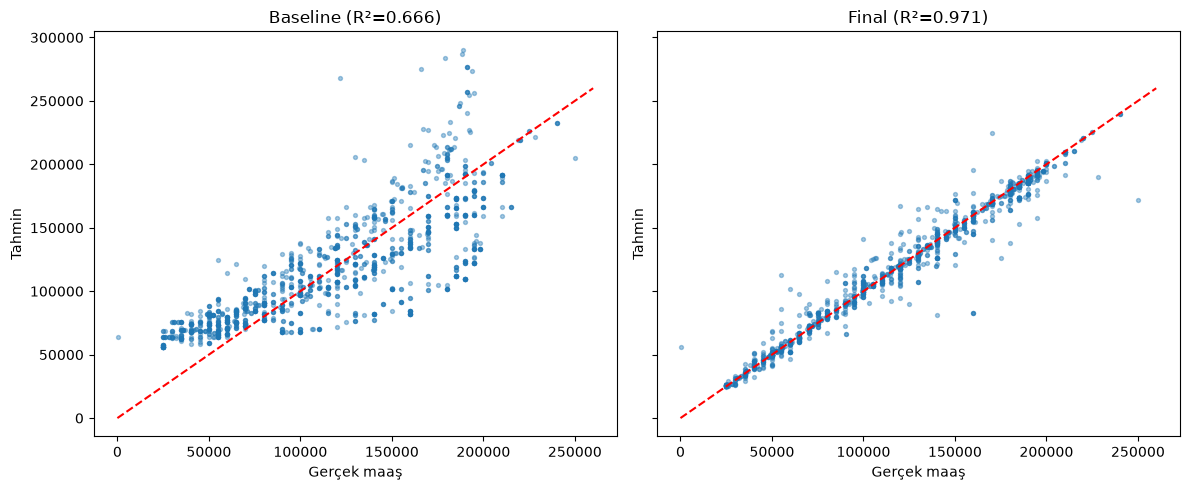

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, p, title in [(ax[0], base_pred, f"Baseline (R²={baseline['R2']:.3f})"),
                    (ax[1], preds[final_name], f"Final (R²={f['R2']:.3f})")]:
    a.scatter(y_test, p, s=8, alpha=.4)
    a.plot([0, 260000], [0, 260000], "r--")
    a.set_title(title); a.set_xlabel("Gerçek maaş"); a.set_ylabel("Tahmin")
plt.tight_layout(); plt.show()

## 8. Dürüstlük kontrolü: tekrar eden satırlar

Veri setinde **6698 satırın yalnızca 1787'si benzersiz**; geri kalanı birebir kopya. Rastgele split yapınca aynı kişi hem train'de hem test'te olabiliyor. Ağaç modelleri bunu "ezberleyebilir", bu yüzden yukarıdaki R² biraz iyimser.

Bunu kontrol etmek için **GroupKFold** kullanıyoruz: birebir aynı satırlar her zaman aynı kat'a düşer, yani test edilen satırın kopyası train'de olamaz. Bu daha zor ve daha gerçekçi bir sınav.

In [9]:
from sklearn.model_selection import GroupKFold, cross_val_score
print("Benzersiz satır:", len(raw.drop_duplicates()), "/", len(raw))
groups = pd.factorize(raw.astype(str).agg("|".join, axis=1))[0]
cv = GroupKFold(n_splits=5)

base_pipe = make_pipeline(StandardScaler(), LinearRegression())
g_base  = cross_val_score(base_pipe, Xb, yb, cv=cv, groups=groups, scoring="r2")
g_final = cross_val_score(models[final_name], df, y, cv=cv, groups=groups, scoring="r2")
print(f"GroupKFold R2  baseline: {g_base.mean():.4f}   final: {g_final.mean():.4f}")

Benzersiz satır: 1787 / 6698


GroupKFold R2  baseline: 0.6529   final: 0.9070


## 9. Model neye bakıyor? (özellik önemi)

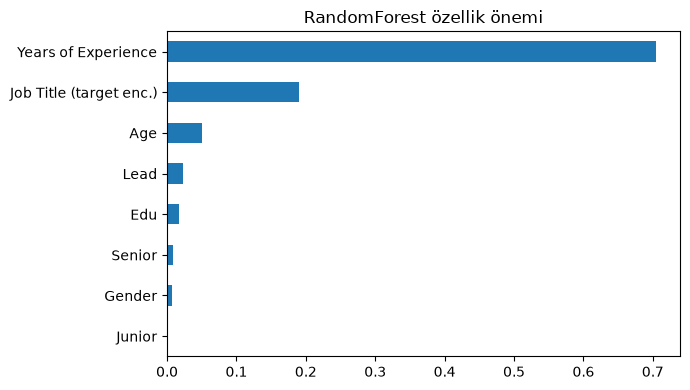

In [10]:
imp = rf.named_steps["randomforestregressor"].feature_importances_
names = num_cols + ["Gender", "Job Title (target enc.)"]
pd.Series(imp, index=names).sort_values().plot.barh(figsize=(7, 4), title="RandomForest özellik önemi")
plt.tight_layout(); plt.show()

## 10. Sonuç

- Sadece **veri temizliği + doğru kodlama** (OneHot) ile bile lineer model 0.67'den ~0.84'e çıkıyor.
- **TargetEncoder + ağaç tabanlı ensemble** ile test R² ~0.97'ye, ortalama mutlak hata (MAE) 24.448 $'dan 4.610 $'a iniyor (%81 azalma).
- Kopya satırlar ayrı tutulduğunda bile (GroupKFold) final model 0.907, baseline 0.653 → fark gerçek, ezberden kaynaklanmıyor.